# PART 1: AUTOENCODER

## 1. LOAD MNIST
Read the raw files from `../CV/archive` → numpy arrays: 60,000 train + 10,000 test images, 28×28, pixels 0–255. Fix the random **seed = 42**.

(60000, 28, 28) (10000, 28, 28)


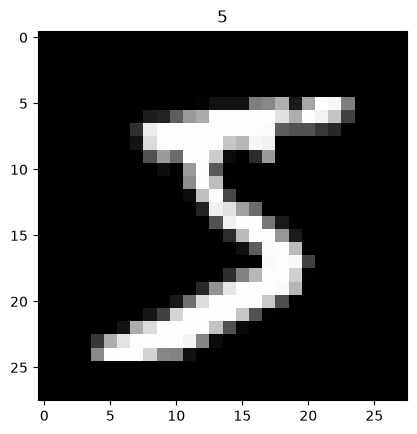

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

torch.manual_seed(42)   # same random start every run -> repeatable results

DATA = '../CV/archive'

def load_images(path):
    raw = open(path, 'rb').read()
    n    = int.from_bytes(raw[4:8], 'big')    # number of images
    rows = int.from_bytes(raw[8:12], 'big')   # 28
    cols = int.from_bytes(raw[12:16], 'big')  # 28
    return np.frombuffer(raw, dtype=np.uint8, offset=16).reshape(n, rows, cols)

def load_labels(path):
    return np.frombuffer(open(path, 'rb').read(), dtype=np.uint8, offset=8)

train_images = load_images(f'{DATA}/train-images.idx3-ubyte')
train_labels = load_labels(f'{DATA}/train-labels.idx1-ubyte')
test_images  = load_images(f'{DATA}/t10k-images.idx3-ubyte')
test_labels  = load_labels(f'{DATA}/t10k-labels.idx1-ubyte')

print(train_images.shape, test_images.shape)   # (60000, 28, 28) (10000, 28, 28)
plt.imshow(train_images[0], cmap='gray'); plt.title(train_labels[0]);

## 2. CONV ENCODER: IMAGE → CODE z
2 convolutions shrink the image (28 → 14 → 7), then 2 linear layers squeeze it to `latent_size` numbers.

In [2]:
from torch import nn

class Encoder(nn.Module):
    def __init__(self, latent_size):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=4, stride=2, padding=1),   # (1, 28, 28)  -> (32, 14, 14)
            nn.LeakyReLU(0.2),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),  # (32, 14, 14) -> (64, 7, 7)
            nn.LeakyReLU(0.2),
            nn.Flatten(),                                           # (64, 7, 7)   -> 3136 numbers
            nn.Linear(64 * 7 * 7, 512),                             # 3136 -> 512
            nn.LeakyReLU(0.2),
            nn.Linear(512, latent_size),                            # 512  -> latent_size (the code z)
        )

    def forward(self, x):          # x: (batch, 1, 28, 28)
        return self.net(x)         # z: (batch, latent_size)


# quick test with random "images"
enc = Encoder(latent_size=16)
x = torch.rand(4, 1, 28, 28)
print(x.shape, '->', enc(x).shape)    # torch.Size([4, 1, 28, 28]) -> torch.Size([4, 16])

torch.Size([4, 1, 28, 28]) -> torch.Size([4, 16])


## 3. MLP ENCODER: IMAGE → CODE z
Flatten the image to 784 numbers, then 2 linear layers. **No built-in locality.** Prints the parameter count of both encoders.

In [3]:
class MLPEncoder(nn.Module):
    def __init__(self, latent_size):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),                  # (1, 28, 28) -> 784 numbers
            nn.Linear(784, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, latent_size),   # 256 -> latent_size (the code z)
        )

    def forward(self, x):
        return self.net(x)


torch.manual_seed(42)
mlp_enc = MLPEncoder(latent_size=16)
print(x.shape, '->', mlp_enc(x).shape)    # same input and output shape as the conv Encoder

count = lambda model: sum(p.numel() for p in model.parameters())
print('conv encoder parameters:', count(enc))
print('MLP encoder parameters: ', count(mlp_enc))

torch.Size([4, 1, 28, 28]) -> torch.Size([4, 16])
conv encoder parameters: 1647728
MLP encoder parameters:  205072


## 4. DECODERS: CODE z → IMAGE
Mirror images of the two encoders. **Sigmoid** at the end keeps output pixels between 0 and 1.

In [4]:
class Decoder(nn.Module):
    # mirror of the conv Encoder: code z -> image
    def __init__(self, latent_size):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_size, 512),                                     # latent_size -> 512
            nn.LeakyReLU(0.2),
            nn.Linear(512, 64 * 7 * 7),                                      # 512 -> 3136
            nn.LeakyReLU(0.2),
            nn.Unflatten(1, (64, 7, 7)),                                     # 3136 -> (64, 7, 7)
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),  # -> (32, 14, 14)
            nn.LeakyReLU(0.2),
            nn.ConvTranspose2d(32, 1, kernel_size=4, stride=2, padding=1),   # -> (1, 28, 28)
            nn.Sigmoid(),                                                    # pixels between 0 and 1
        )

    def forward(self, z):
        return self.net(z)


class MLPDecoder(nn.Module):
    # mirror of the MLPEncoder: code z -> image
    def __init__(self, latent_size):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_size, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 784),
            nn.Sigmoid(),                  # pixels between 0 and 1
            nn.Unflatten(1, (1, 28, 28)),  # 784 numbers -> (1, 28, 28) image
        )

    def forward(self, z):
        return self.net(z)


dec = Decoder(latent_size=16)
mlp_dec = MLPDecoder(latent_size=16)
print('conv:', x.shape, '->', enc(x).shape, '->', dec(enc(x)).shape)
print('MLP: ', x.shape, '->', mlp_enc(x).shape, '->', mlp_dec(mlp_enc(x)).shape)
print('conv decoder parameters:', count(dec))
print('MLP decoder parameters: ', count(mlp_dec))

conv: torch.Size([4, 1, 28, 28]) -> torch.Size([4, 16]) -> torch.Size([4, 1, 28, 28])
MLP:  torch.Size([4, 1, 28, 28]) -> torch.Size([4, 16]) -> torch.Size([4, 1, 28, 28])
conv decoder parameters: 1650785
MLP decoder parameters:  205840


## 5. DATA PREP: 0–255 → 0–1 TENSORS
Shape `(N, 1, 28, 28)`. Split: **55k train / 5k validation / 10k test**.

In [5]:
# numpy (N, 28, 28) with values 0..255  ->  torch tensor (N, 1, 28, 28) with values 0..1
def to_tensor(images):
    return torch.from_numpy(images.copy()).float().div(255).unsqueeze(1)

train_x = to_tensor(train_images[:55000])   # 55,000 images to learn from
val_x   = to_tensor(train_images[55000:])   #  5,000 images to watch progress during training
test_x  = to_tensor(test_images)            # 10,000 images for the final score

print(train_x.shape, val_x.shape, test_x.shape)
print('pixel range:', train_x.min().item(), '...', train_x.max().item())

torch.Size([55000, 1, 28, 28]) torch.Size([5000, 1, 28, 28]) torch.Size([10000, 1, 28, 28])
pixel range: 0.0 ... 1.0


## 6. LOSS = MSE, TRAINING LOOP
`AutoEncoder` joins any encoder + decoder. `train()` minimizes **MSE(output, input)**, since the target is the input itself. `evaluate()` = average MSE on a dataset.

In [6]:
device = 'mps' if torch.backends.mps.is_available() else 'cpu'   # Mac GPU if available

loss_fn = nn.MSELoss()   # average of (reconstructed pixel - original pixel)^2


class AutoEncoder(nn.Module):
    # glues any encoder and any decoder together: x -> z -> x_hat
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, x):
        return self.decoder(self.encoder(x))


def evaluate(model, data):
    # average MSE on a dataset, without training
    model.eval()
    total = 0
    with torch.no_grad():
        for x in data.split(1000):
            x = x.to(device)
            total += loss_fn(model(x), x).item() * len(x)
    return total / len(data)


def train(model, epochs=10, lr=1e-3, batch_size=128, verbose=True):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = torch.utils.data.DataLoader(train_x, batch_size=batch_size, shuffle=True, drop_last=True)
    history = {'train': [], 'val': []}

    for epoch in range(epochs):
        model.train()
        total = 0
        for x in loader:
            x = x.to(device)
            loss = loss_fn(model(x), x)   # the target is the input itself

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item()

        history['train'].append(total / len(loader))
        history['val'].append(evaluate(model, val_x))
        if verbose:
            print(f"epoch {epoch + 1:2d}: train MSE {history['train'][-1]:.5f}   val MSE {history['val'][-1]:.5f}")

    return history

## 7. TRAIN: CONV AUTOENCODER (latent 16)
Seed 42, 10 epochs → **test MSE**.

In [7]:
# Autoencoder 1: conv encoder + conv decoder
torch.manual_seed(42)
decoder = Decoder(latent_size=16)          # decoder created FIRST -> identical starting weights in both models
encoder = Encoder(latent_size=16)
conv_ae = AutoEncoder(encoder, decoder)

conv_history = train(conv_ae, epochs=10)
print('conv encoder  test MSE:', evaluate(conv_ae, test_x))

epoch  1: train MSE 0.02862   val MSE 0.01117


epoch  2: train MSE 0.00984   val MSE 0.00907


epoch  3: train MSE 0.00839   val MSE 0.00813


epoch  4: train MSE 0.00766   val MSE 0.00761


epoch  5: train MSE 0.00721   val MSE 0.00729


epoch  6: train MSE 0.00687   val MSE 0.00703


epoch  7: train MSE 0.00662   val MSE 0.00690


epoch  8: train MSE 0.00640   val MSE 0.00673


epoch  9: train MSE 0.00623   val MSE 0.00668


epoch 10: train MSE 0.00607   val MSE 0.00652
conv encoder  test MSE: 0.006431573908776045


## 8. TRAIN: MLP AUTOENCODER (latent 16)
Same seed, epochs and loop as step 7 → **compare test MSE: conv vs MLP**.

In [8]:
# Autoencoder 2: MLP encoder + MLP decoder
torch.manual_seed(42)
decoder = MLPDecoder(latent_size=16)
encoder = MLPEncoder(latent_size=16)
mlp_ae = AutoEncoder(encoder, decoder)

mlp_history = train(mlp_ae, epochs=10)
print('MLP autoencoder  test MSE:', evaluate(mlp_ae, test_x))

epoch  1: train MSE 0.04254   val MSE 0.02254


epoch  2: train MSE 0.01944   val MSE 0.01725


epoch  3: train MSE 0.01636   val MSE 0.01533


epoch  4: train MSE 0.01487   val MSE 0.01423


epoch  5: train MSE 0.01391   val MSE 0.01347


epoch  6: train MSE 0.01323   val MSE 0.01296


epoch  7: train MSE 0.01272   val MSE 0.01248


epoch  8: train MSE 0.01231   val MSE 0.01216


epoch  9: train MSE 0.01195   val MSE 0.01185


epoch 10: train MSE 0.01165   val MSE 0.01167
MLP autoencoder  test MSE: 0.011514053866267204


## RESULT 1: CONV BEATS MLP (≈1.8× LOWER ERROR)

| latent 16, 10 epochs | Conv AE | MLP AE |
|---|---|---|
| **test MSE** | **0.0064** | 0.0115 |
| parameters | 3.30M | 0.41M |

- Conv is ahead from the **first epoch**, and stays ahead at **every latent size** in experiment 9.
- **Why:** convolutions have **built-in locality**. They look at neighbouring pixels together and reuse the same filter everywhere. The MLP must learn which pixels are neighbours from data.
- The MLP is **underfitting**: train ≈ val error, still falling at epoch 10.
- **Caveat:** conv is **8× bigger**, so part of the gain may come from size, not only locality. A bigger MLP would make the comparison fairer.

## 9. EXPERIMENT: LATENT SIZE 2 → 128
Train **both** architectures for every latent size. Prints **compression ratio** (784 / size) and **test MSE** for each. Models and results are stored for the plot and pictures.

In [9]:
# Latent-size experiment: train BOTH architectures for every latent size
# (new variable names, so conv_ae / mlp_ae from the comparison above stay untouched)

latent_sizes = [2, 4, 8, 16, 32, 64, 128]
sweep_mse    = {'conv': {}, 'mlp': {}}   # test MSE for each architecture and latent size
sweep_models = {'conv': {}, 'mlp': {}}   # trained models, kept to look at reconstructions later

for d in latent_sizes:
    torch.manual_seed(42)
    conv = AutoEncoder(Encoder(d), Decoder(d))
    train(conv, epochs=10, verbose=False)

    torch.manual_seed(42)
    mlp = AutoEncoder(MLPEncoder(d), MLPDecoder(d))
    train(mlp, epochs=10, verbose=False)

    sweep_models['conv'][d], sweep_models['mlp'][d] = conv, mlp
    sweep_mse['conv'][d] = evaluate(conv, test_x)
    sweep_mse['mlp'][d]  = evaluate(mlp, test_x)
    print(f"latent {d:3d}  ({784 // d:3d}x compression):   conv test MSE {sweep_mse['conv'][d]:.5f}   MLP test MSE {sweep_mse['mlp'][d]:.5f}")

latent   2  (392x compression):   conv test MSE 0.03973   MLP test MSE 0.04457


latent   4  (196x compression):   conv test MSE 0.02628   MLP test MSE 0.03106


latent   8  ( 98x compression):   conv test MSE 0.01352   MLP test MSE 0.01950


latent  16  ( 49x compression):   conv test MSE 0.00652   MLP test MSE 0.01144


latent  32  ( 24x compression):   conv test MSE 0.00342   MLP test MSE 0.00627


latent  64  ( 12x compression):   conv test MSE 0.00230   MLP test MSE 0.00390


latent 128  (  6x compression):   conv test MSE 0.00245   MLP test MSE 0.00312


## 10. PLOT: RECONSTRUCTION ERROR vs LATENT SIZE
Both axes logarithmic. Look for the **"elbow"**: the point after which a bigger code barely helps.

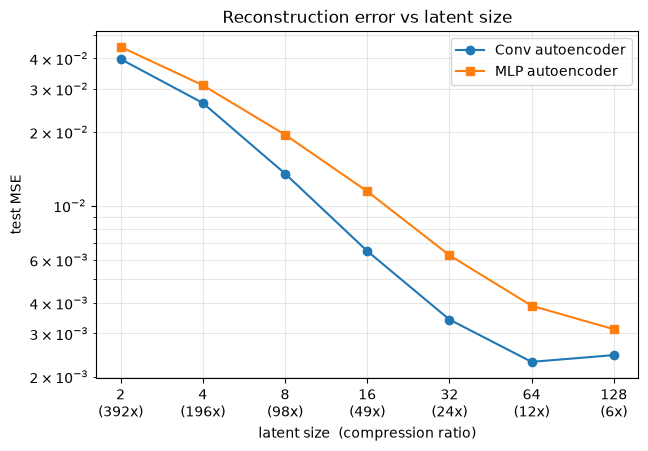

In [10]:
plt.figure(figsize=(7, 4.5))
plt.plot(latent_sizes, [sweep_mse['conv'][d] for d in latent_sizes], 'o-', label='Conv autoencoder')
plt.plot(latent_sizes, [sweep_mse['mlp'][d] for d in latent_sizes], 's-', label='MLP autoencoder')

plt.xscale('log', base=2)
plt.yscale('log')
plt.xticks(latent_sizes, [f'{d}\n({784 // d}x)' for d in latent_sizes])   # latent size + compression ratio
plt.xlabel('latent size  (compression ratio)')
plt.ylabel('test MSE')
plt.title('Reconstruction error vs latent size')
plt.grid(alpha=0.3, which='both')
plt.legend()
plt.show()

## 11. PICTURES: SAMPLE RECONSTRUCTIONS
Top row = **original** test images. Every next row = the same images rebuilt with a **bigger code**. One figure per architecture.

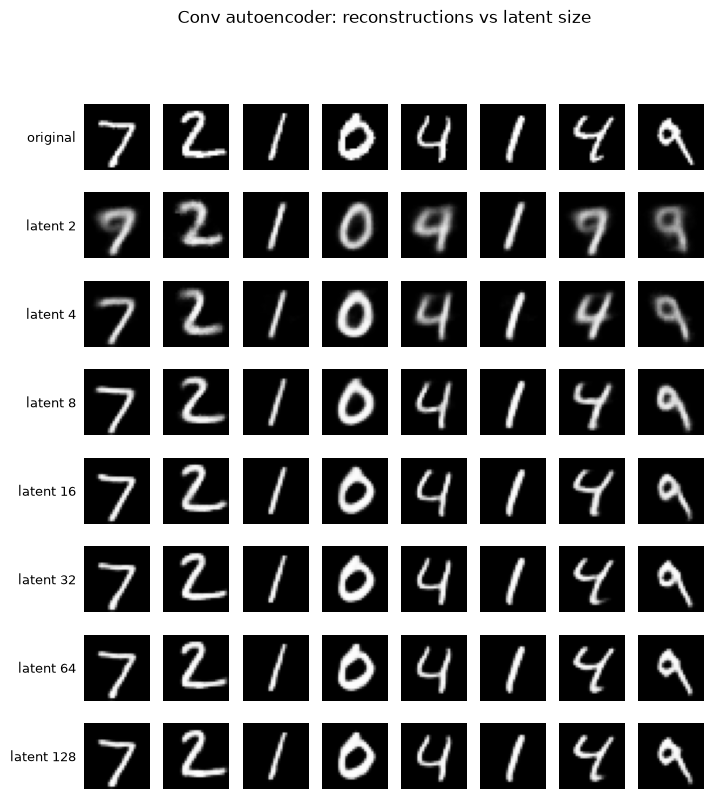

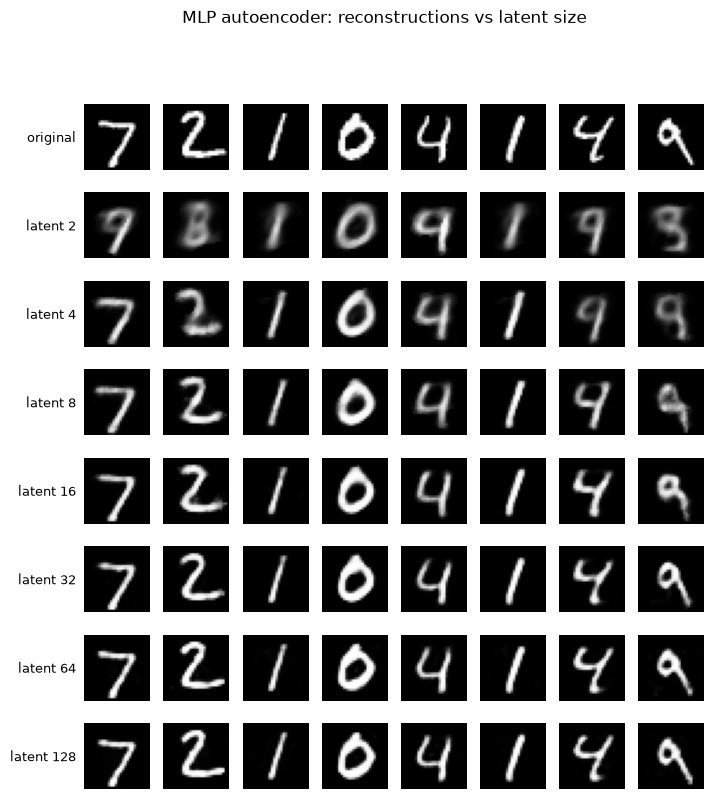

In [11]:
images = test_x[:8]   # 8 test images the models never trained on

for name, title in [('conv', 'Conv autoencoder'), ('mlp', 'MLP autoencoder')]:
    rows = [('original', images)]
    with torch.no_grad():
        for d in latent_sizes:
            model = sweep_models[name][d].eval()
            rows.append((f'latent {d}', model(images.to(device)).cpu()))

    fig, axes = plt.subplots(len(rows), 8, figsize=(8, 9))
    for r, (label, imgs) in enumerate(rows):
        for c in range(8):
            axes[r, c].imshow(imgs[c, 0], cmap='gray', vmin=0, vmax=1)
            axes[r, c].axis('off')
        axes[r, 0].text(-4, 14, label, ha='right', va='center', fontsize=9)   # row label on the left
    fig.suptitle(f'{title}: reconstructions vs latent size')
    plt.show()

## RESULT 2: BIGGER CODE = LESS INFORMATION LOST, BUT WITH DIMINISHING RETURNS

| latent size | 2 | 4 | 8 | 16 | 32 | 64 | 128 |
|---|---|---|---|---|---|---|---|
| compression | 392× | 196× | 98× | 49× | 24× | 12× | 6× |
| **conv MSE** | 0.0397 | 0.0263 | 0.0135 | 0.0065 | 0.0034 | **0.0023** | 0.0025 |
| **MLP MSE** | 0.0446 | 0.0311 | 0.0195 | 0.0114 | 0.0063 | 0.0039 | **0.0031** |

**The hypothesis holds:** a bigger code can keep more information, so it needs less squeezing. Conv error drops **17×** from latent 2 to 64.

**BUT: there is an "elbow" at latent 64 (conv).**
- 2 → 32: big gains (each doubling roughly halves the error).
- 64 → 128: flat. Conv at 128 is **not better** than at 64.
- **MLP:** no clear elbow yet; it is still improving at 128 (it is underfitting).
- **Why:** MNIST digits have few real "degrees of freedom" (shape, thickness, slant…). Once the code can describe them, extra numbers only add tiny details.

**What the pictures show:**
- **latent 2:** blurry, and sometimes the **wrong digit** (4 → 9; for MLP 2 → 8).
- **latent 4–8:** right digit, but the personal style is lost.
- **latent 16+:** almost identical to the original.

**Trade-off:** less error **=** less compression. And a too-large code gives the network less reason to learn the structure of digits; at 784 it could just copy pixels.

# PART 2: VARIATIONAL AUTOENCODER (VAE)

**Problem of the plain AE:** it cannot **generate**. Random codes land in "holes" the decoder never saw.

**VAE fix:**
- Encoder outputs a **cloud** (center **μ**, spread **σ**) instead of a point.
- Loss = **reconstruction + KL**. KL pulls every cloud toward **N(0, I)**, so the codes fill one known blob with no holes.
- **Generate:** `z ~ N(0, I)` → decoder → new image.

## 12. LOAD FASHION-MNIST + BINARIZE VAL/TEST
Same loader as MNIST. Pixels become 0/1 coin flips (P(white) = brightness), so BCE is a proper likelihood. Val/test are binarized **once** with a fixed seed, so every model is scored on the same images.

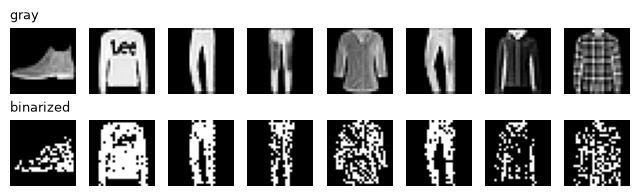

In [12]:
FASHION = '../CV/fashion'
fashion_train_images = load_images(f'{FASHION}/train-images-idx3-ubyte')
fashion_test_images  = load_images(f'{FASHION}/t10k-images-idx3-ubyte')
fashion_test_labels  = load_labels(f'{FASHION}/t10k-labels-idx1-ubyte')
FASHION_CLASSES = ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Boot']

f_train_x = to_tensor(fashion_train_images[:55000])   # same split as MNIST
f_val_x   = to_tensor(fashion_train_images[55000:])
f_test_x  = to_tensor(fashion_test_images)

# binarize validation and test ONCE: every pixel -> 1 with probability = its brightness
torch.manual_seed(42)
val_bin,   test_bin   = torch.bernoulli(val_x),   torch.bernoulli(test_x)     # MNIST
f_val_bin, f_test_bin = torch.bernoulli(f_val_x), torch.bernoulli(f_test_x)   # Fashion

fig, axes = plt.subplots(2, 8, figsize=(8, 2.2))
for i in range(8):
    axes[0, i].imshow(f_test_x[i, 0], cmap='gray'); axes[0, i].axis('off')
    axes[1, i].imshow(f_test_bin[i, 0], cmap='gray'); axes[1, i].axis('off')
axes[0, 0].set_title('gray', loc='left', fontsize=9)
axes[1, 0].set_title('binarized', loc='left', fontsize=9)
plt.show()

## 13. VAE MODEL
Reuses the conv **Encoder** and **Decoder** from Part 1. The encoder now outputs **2 × latent** numbers = **μ and log σ²**.
**Reparameterization trick:** `z = μ + σ · ε`, with ε ~ N(0, I). The randomness sits in ε, so gradients can flow through μ and σ.

In [13]:
class VAE(nn.Module):
    def __init__(self, latent_size):
        super().__init__()
        self.latent_size = latent_size
        self.encoder = Encoder(2 * latent_size)   # outputs mu AND log-variance
        self.decoder = Decoder(latent_size)       # same conv decoder as in Part 1 (ends with Sigmoid)

    def forward(self, x):
        mu, logvar = self.encoder(x).chunk(2, dim=1)   # split the 2*latent numbers into two halves
        std = torch.exp(0.5 * logvar)                  # sigma = exp(log(sigma^2) / 2)
        z = mu + std * torch.randn_like(std)           # reparameterization trick
        return self.decoder(z), mu, logvar

    def sample(self, n):
        z = torch.randn(n, self.latent_size, device=device)   # z ~ N(0, I)
        return self.decoder(z)                                 # -> n brand-new images


torch.manual_seed(42)
vae = VAE(latent_size=16)
x_hat, mu, logvar = vae(x)          # x = the 4 random "images" from step 2 (shape test only)
print('input', x.shape, '-> mu', mu.shape, ' logvar', logvar.shape, '-> output', x_hat.shape)

input torch.Size([4, 1, 28, 28]) -> mu torch.Size([4, 16])  logvar torch.Size([4, 16]) -> output torch.Size([4, 1, 28, 28])


## 14. LOSS = RECONSTRUCTION (BCE) + KL
- **BCE:** the decoder outputs, per pixel, the **probability it is white**. BCE = −log-likelihood of the real image.
- **KL** (closed form): how far each cloud N(μ, σ²) is from N(0, I).
- **recon + KL = −ELBO**, an upper bound on −log p(x). Both are in **nats per image**: lower = better.

In [14]:
import torch.nn.functional as F

def vae_loss(x_hat, x, mu, logvar):
    # both terms in nats per image: summed over pixels / latent dims, averaged over the batch
    recon = F.binary_cross_entropy(x_hat, x, reduction='sum') / len(x)
    kl = -0.5 * torch.sum(1 + logvar - mu ** 2 - logvar.exp()) / len(x)
    return recon, kl


def evaluate_vae(model, data_bin):
    # average recon, KL and -ELBO on a (binarized) dataset, without training
    model.eval()
    recon_sum, kl_sum = 0, 0
    with torch.no_grad():
        for x in data_bin.split(1000):
            x = x.to(device)
            x_hat, mu, logvar = model(x)
            recon, kl = vae_loss(x_hat, x, mu, logvar)
            recon_sum += recon.item() * len(x)
            kl_sum += kl.item() * len(x)
    n = len(data_bin)
    return {'recon': recon_sum / n, 'kl': kl_sum / n, 'nelbo': (recon_sum + kl_sum) / n}

## 15. VAE TRAINING LOOP + KL WARM-UP
- **Dynamic binarization:** every batch, gray pixels → fresh random 0/1 (`torch.bernoulli`).
- **KL warm-up:** loss = recon + **β** · KL, with β growing **0 → 1** over the first 10 epochs. First the model learns to reconstruct, then the latent space is organized. This prevents **"posterior collapse"** (the model ignoring z).
- Printed −ELBO always uses β = 1, so numbers are comparable.

In [15]:
def train_vae(model, train_data, val_bin, epochs=30, lr=1e-3, batch_size=128, warmup_epochs=10):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size, shuffle=True, drop_last=True)
    history = {'train': [], 'val': [], 'val_recon': [], 'val_kl': [], 'beta': []}

    for epoch in range(epochs):
        beta = min(1.0, epoch / warmup_epochs)          # KL warm-up: 0, 0.1, 0.2, ..., 1
        model.train()
        total = 0
        for x in loader:
            x = torch.bernoulli(x).to(device)            # dynamic binarization
            x_hat, mu, logvar = model(x)
            recon, kl = vae_loss(x_hat, x, mu, logvar)
            loss = recon + beta * kl

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += (recon + kl).item()

        val = evaluate_vae(model, val_bin)
        history['train'].append(total / len(loader))
        history['val'].append(val['nelbo'])
        history['val_recon'].append(val['recon'])
        history['val_kl'].append(val['kl'])
        history['beta'].append(beta)
        if epoch == 0 or (epoch + 1) % 5 == 0:
            print(f"epoch {epoch + 1:2d}  beta {beta:.1f}   train -ELBO {history['train'][-1]:6.2f}   "
                  f"val -ELBO {val['nelbo']:6.2f}  (recon {val['recon']:6.2f} + KL {val['kl']:5.2f})")
    return history

## 16. TRAIN VAE ON MNIST (latent 16, 30 epochs)

In [16]:
torch.manual_seed(42)
vae_mnist = VAE(latent_size=16)
hist_mnist = train_vae(vae_mnist, train_x, val_bin, epochs=30)

epoch  1  beta 0.0   train -ELBO 244.94   val -ELBO 235.78  (recon  72.39 + KL 163.38)


epoch  5  beta 0.4   train -ELBO 101.00   val -ELBO 100.81  (recon  66.50 + KL 34.31)


epoch 10  beta 0.9   train -ELBO  95.50   val -ELBO  96.29  (recon  69.42 + KL 26.88)


epoch 15  beta 1.0   train -ELBO  93.76   val -ELBO  94.70  (recon  69.06 + KL 25.64)


epoch 20  beta 1.0   train -ELBO  92.59   val -ELBO  93.46  (recon  68.43 + KL 25.03)


epoch 25  beta 1.0   train -ELBO  91.77   val -ELBO  92.71  (recon  68.24 + KL 24.48)


epoch 30  beta 1.0   train -ELBO  91.11   val -ELBO  92.49  (recon  68.09 + KL 24.40)


## 17. TRAIN VAE ON FASHION-MNIST (same settings)

In [17]:
torch.manual_seed(42)
vae_fashion = VAE(latent_size=16)
hist_fashion = train_vae(vae_fashion, f_train_x, f_val_bin, epochs=30)

epoch  1  beta 0.0   train -ELBO 357.58   val -ELBO 335.04  (recon 217.60 + KL 117.44)


epoch  5  beta 0.4   train -ELBO 242.17   val -ELBO 242.76  (recon 213.08 + KL 29.68)


epoch 10  beta 0.9   train -ELBO 235.86   val -ELBO 237.09  (recon 216.45 + KL 20.64)


epoch 15  beta 1.0   train -ELBO 234.28   val -ELBO 235.76  (recon 216.62 + KL 19.14)


epoch 20  beta 1.0   train -ELBO 233.34   val -ELBO 234.76  (recon 216.11 + KL 18.65)


epoch 25  beta 1.0   train -ELBO 232.77   val -ELBO 234.16  (recon 215.86 + KL 18.30)


epoch 30  beta 1.0   train -ELBO 232.31   val -ELBO 234.06  (recon 215.63 + KL 18.43)


## 18. LEARNING CURVES
Left: total **−ELBO**. Middle: **reconstruction** part. Right: **KL** part, with β dotted. Watch what reconstruction does **while β grows** (epochs 1–10).

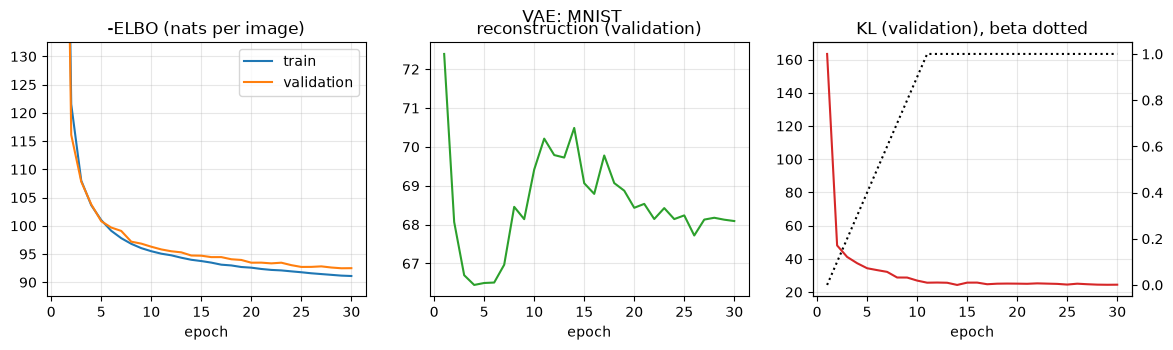

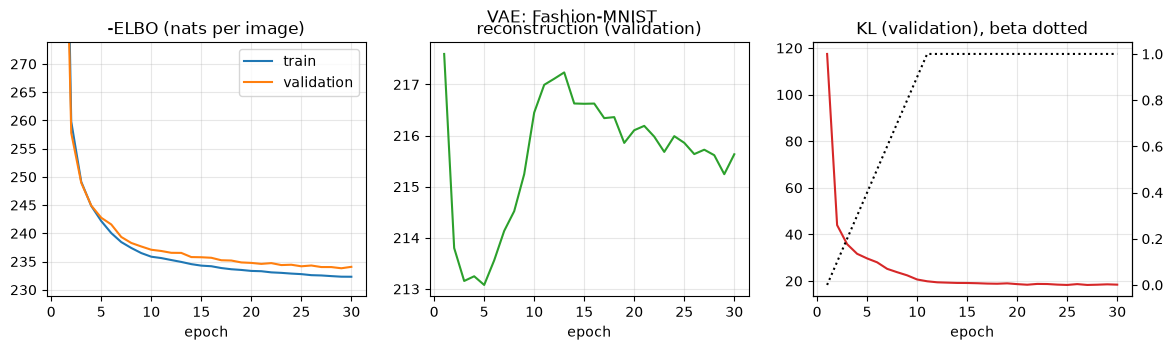

In [18]:
for hist, name in [(hist_mnist, 'MNIST'), (hist_fashion, 'Fashion-MNIST')]:
    epochs = range(1, len(hist['val']) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.3))

    axes[0].plot(epochs, hist['train'], label='train')
    axes[0].plot(epochs, hist['val'], label='validation')
    axes[0].set_ylim(min(hist['val']) - 5, min(hist['val']) + 40)   # zoom in, skip the huge first epoch
    axes[0].set_title('-ELBO (nats per image)')
    axes[0].legend()

    axes[1].plot(epochs, hist['val_recon'], color='C2')
    axes[1].set_title('reconstruction (validation)')

    axes[2].plot(epochs, hist['val_kl'], color='C3')
    axes[2].set_title('KL (validation), beta dotted')
    axes[2].twinx().plot(epochs, hist['beta'], 'k:')

    for ax in axes:
        ax.set_xlabel('epoch')
        ax.grid(alpha=0.3)
    fig.suptitle(f'VAE: {name}')
    plt.show()

## 19. GENERATE NEW IMAGES: z ~ N(0, I) → DECODER
64 random codes per dataset → **brand-new images** the model never saw. This is what the plain autoencoder could **not** do.

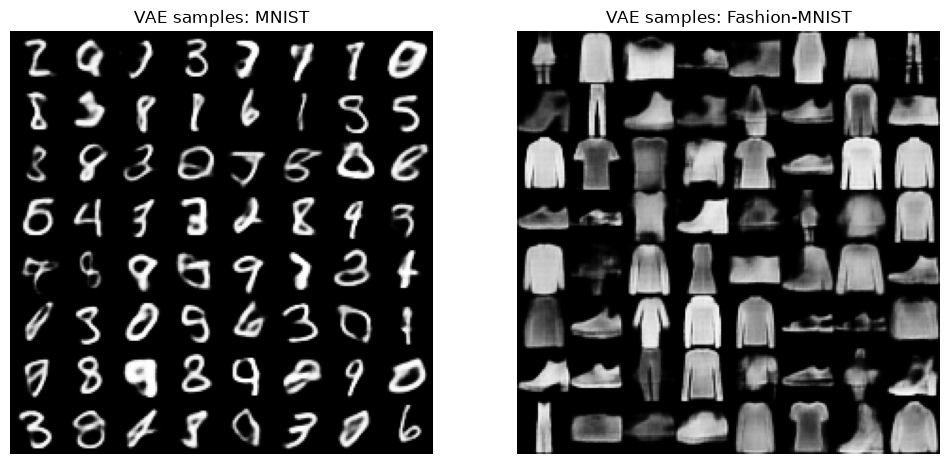

In [19]:
def show_grid(images, nrow, ax, title):
    # put N small 28x28 images into one big picture
    images = images.detach().cpu()[:, 0]                    # (N, 28, 28)
    ncol = len(images) // nrow
    rows = [torch.cat(list(images[r * ncol:(r + 1) * ncol]), dim=1) for r in range(nrow)]
    ax.imshow(torch.cat(rows, dim=0), cmap='gray', vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis('off')


torch.manual_seed(42)
vae_mnist.eval(); vae_fashion.eval()
with torch.no_grad():
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    show_grid(vae_mnist.sample(64), 8, axes[0], 'VAE samples: MNIST')
    show_grid(vae_fashion.sample(64), 8, axes[1], 'VAE samples: Fashion-MNIST')
    plt.show()

## 20. RECONSTRUCTIONS: ORIGINAL vs VAE
Top row = **test images**, bottom row = **VAE reconstruction** (decoded from the cloud center μ).

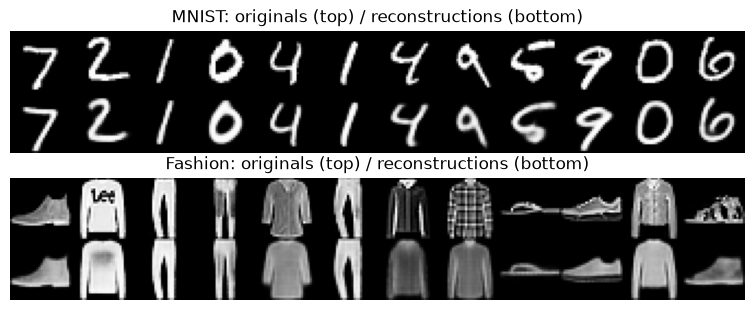

In [20]:
with torch.no_grad():
    fig, axes = plt.subplots(2, 1, figsize=(12, 3.5))
    for ax, model, data, name in [(axes[0], vae_mnist, test_x, 'MNIST'), (axes[1], vae_fashion, f_test_x, 'Fashion')]:
        originals = data[:12].to(device)
        mu, logvar = model.encoder(originals).chunk(2, dim=1)
        rebuilt = model.decoder(mu)                         # use the cloud center, no random noise
        show_grid(torch.cat([originals, rebuilt]), 2, ax, f'{name}: originals (top) / reconstructions (bottom)')
    plt.show()

## 21. COMPARE MNIST vs FASHION: TEST −ELBO + PER CLASS
Table = test numbers (nats per image, **lower = better**). Bars = which **classes** are hardest for the model.

          recon     kl   nelbo
MNIST     67.25  24.32   91.57
Fashion  216.16  18.31  234.47


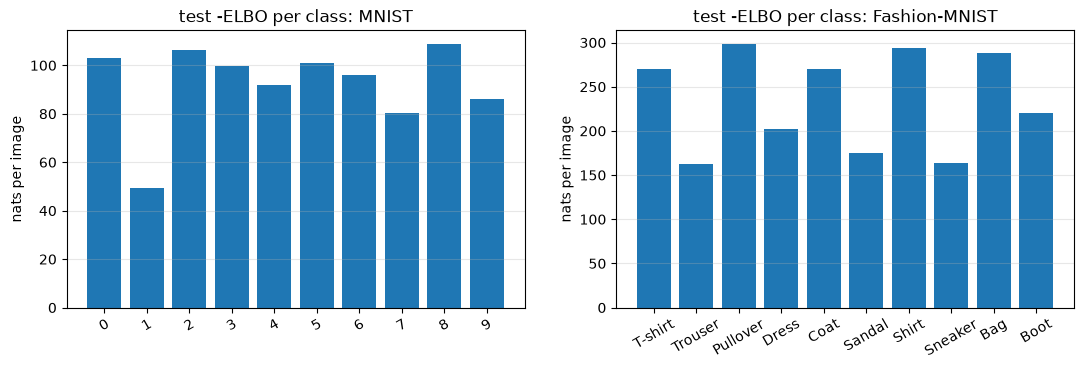

In [21]:
import pandas as pd

torch.manual_seed(42)
results = pd.DataFrame({'MNIST': evaluate_vae(vae_mnist, test_bin),
                        'Fashion': evaluate_vae(vae_fashion, f_test_bin)}).T
print(results.round(2))


def nelbo_per_image(model, data_bin):
    # -ELBO of every single test image (needed to average per class)
    model.eval()
    values = []
    with torch.no_grad():
        for x in data_bin.split(1000):
            x = x.to(device)
            x_hat, mu, logvar = model(x)
            recon = F.binary_cross_entropy(x_hat, x, reduction='none').sum(dim=(1, 2, 3))
            kl = -0.5 * (1 + logvar - mu ** 2 - logvar.exp()).sum(dim=1)
            values.append((recon + kl).cpu())
    return torch.cat(values)


fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, model, data_bin, labels, names, title in [
        (axes[0], vae_mnist, test_bin, test_labels, [str(i) for i in range(10)], 'MNIST'),
        (axes[1], vae_fashion, f_test_bin, fashion_test_labels, FASHION_CLASSES, 'Fashion-MNIST')]:
    per_image = nelbo_per_image(model, data_bin)
    labels = torch.from_numpy(labels.astype('int64'))
    ax.bar(names, [per_image[labels == c].mean().item() for c in range(10)])
    ax.set_title(f'test -ELBO per class: {title}')
    ax.set_ylabel('nats per image')
    ax.tick_params(axis='x', rotation=30)
    ax.grid(alpha=0.3, axis='y')
plt.show()

## RESULT 3: THE VAE GENERATES; MNIST IS EASIER THAN FASHION

| test, nats per image | recon (BCE) | KL | **−ELBO** |
|---|---|---|---|
| **MNIST** | 67.3 | 24.3 | **91.6** |
| **Fashion-MNIST** | 216.2 | 18.3 | **234.5** |

**THE VAE CAN GENERATE.** Random `z ~ N(0, I)` decode into real-looking digits and clothes. The plain autoencoder could not do this.

**KL WARM-UP WORKED:**
- Epoch 1 (β = 0): KL = 163, so the clouds are unconstrained.
- As β → 1, KL falls to ≈ 24 and **reconstruction gets slightly worse** (66.5 → 70). The model gives up a little precision to organize the latent space. After that both improve slowly.
- Train ≈ val (gap ≈ 1.4 nats): **no real overfitting**; still improving at epoch 30.

**MNIST vs FASHION:**
- **−ELBO is 2.6× higher for Fashion.** Clothes have many gray, textured pixels, which is more information per image. So the absolute numbers **can't be compared** across datasets as "better/worse model".
- **Samples:** MNIST = mostly clear digits, some mixed or broken ones. Fashion = clear **silhouettes** (shirts, trousers, shoes, bags) but **blurry, with no textures**.
- **Reconstructions:** MNIST ≈ perfect. Fashion **loses details**: the "Lee" logo and the checkered pattern come back as plain gray.
- **Hardest classes:** MNIST: **1 is easiest** (≈ 50 nats, few pixels), **8, 2, 0 hardest** (≈ 105). Fashion: **trouser, sneaker, sandal easiest** (≈ 165), **pullover, shirt, bag, T-shirt, coat hardest** (≈ 270–300): textured classes, and tops look alike.

**WHY BLURRY:** pixels are predicted independently given z, and only 16 numbers describe a whole image. Details that z can't hold get **averaged** into gray.

# PART 3: f-VAE (VAE + REALNVP FLOW IN THE LATENT SPACE)

**Problem of the VAE:** the prior **N(0, I)** is a round blob, but the real codes form an irregular shape → regions of the blob with no real codes (**"prior holes"**) → broken samples.

**Fix:** a **learned prior**. A RealNVP flow `f` maps a code `z` to `u`, and we ask `u` to look like N(0, I):

**log p(z) = log N(f(z); 0, I) + log |det ∂f/∂z|**

- **Train:** the flow learns jointly with encoder and decoder, putting probability **where the real codes are**.
- **Generate:** `u ~ N(0, I)` → `z = f⁻¹(u)` → decoder.
- **KL** has no formula any more → estimate it with the sampled z: **KL ≈ log q(z|x) − log p_flow(z)**.

## 22. COUPLING LAYER + REALNVP (for a 16-number vector)
Same idea as HW1: the **masked half stays**, the other half is scaled by `exp(s)` and shifted by `t`, both computed from the masked half.
- **Inverse:** `z = (u − t) · exp(−s)`. **Log-det:** `sum(s)`.
- Last layer starts at **zero** → the flow starts as the identity (stable). `tanh` keeps scales small.
- Masks alternate (**even/odd**, then **first/second half**) so every number gets changed.

In [22]:
import math
LOG_2PI = math.log(2 * math.pi)


class CouplingLayer(nn.Module):
    def __init__(self, size, hidden, mask):
        super().__init__()
        self.register_buffer('mask', mask.float())      # 1 = stays the same, 0 = gets transformed
        self.net = nn.Sequential(
            nn.Linear(size, hidden), nn.LeakyReLU(0.2),
            nn.Linear(hidden, hidden), nn.LeakyReLU(0.2),
            nn.Linear(hidden, 2 * size),                 # outputs s and t
        )
        nn.init.zeros_(self.net[-1].weight)              # start as the identity map
        nn.init.zeros_(self.net[-1].bias)

    def _s_t(self, z_fixed):
        s, t = self.net(z_fixed).chunk(2, dim=1)
        s = torch.tanh(s)                                # keep scales between e^-1 and e^1
        return s * (1 - self.mask), t * (1 - self.mask)  # only the NOT-masked half changes

    def forward(self, z):                                # z -> u
        s, t = self._s_t(z * self.mask)
        return z * torch.exp(s) + t, s.sum(dim=1)        # new vector, log-determinant

    def inverse(self, u):                                # u -> z
        s, t = self._s_t(u * self.mask)
        return (u - t) * torch.exp(-s)


class RealNVP(nn.Module):
    def __init__(self, size, n_layers=8, hidden=256):
        super().__init__()
        even = torch.arange(size) % 2 == 0               # mask type 1: even / odd positions
        first_half = torch.arange(size) < size // 2      # mask type 2: first / second half
        masks = []
        for k in range(n_layers):
            base = even if (k // 2) % 2 == 0 else first_half
            masks.append(base if k % 2 == 0 else ~base)  # flip every layer
        self.layers = nn.ModuleList([CouplingLayer(size, hidden, m) for m in masks])

    def forward(self, z):                                # z -> u, total log-determinant
        log_det = 0
        for layer in self.layers:
            z, ld = layer(z)
            log_det = log_det + ld
        return z, log_det

    def inverse(self, u):                                # u -> z (used for sampling)
        for layer in reversed(self.layers):
            u = layer.inverse(u)
        return u

    def log_prob(self, z):                               # log p(z) of the learned prior
        u, log_det = self(z)
        return (-0.5 * u ** 2 - 0.5 * LOG_2PI).sum(dim=1) + log_det

## 23. CHECK THE FLOW IS CORRECT
1. **Invertible:** forward then inverse must give back the same vector.
2. **Log-det correct:** our cheap `sum(s)` must equal the real log-det of the full 16×16 Jacobian.

Weights are randomized first, because a fresh flow is the identity and the test would be too easy.

In [23]:
torch.manual_seed(42)
flow = RealNVP(16, n_layers=8, hidden=64)
with torch.no_grad():
    for p in flow.parameters():
        p += 0.1 * torch.randn_like(p)

z = torch.randn(4, 16)
u, log_det = flow(z)
print('invertible:', torch.allclose(flow.inverse(u), z, atol=1e-5))

J = torch.autograd.functional.jacobian(lambda v: flow(v.unsqueeze(0))[0][0], z[0])
print('log-det from the flow:', round(log_det[0].item(), 5), '   real:', round(torch.slogdet(J)[1].item(), 5))

invertible: True
log-det from the flow: 1.523    real: 1.523


## 24. f-VAE MODEL + LOSS
`FlowVAE` **inherits** the VAE (same encoder, decoder, reparameterization) and adds `self.prior = RealNVP(...)`.
- `forward` also returns **z**, needed for the KL estimate.
- `sample`: **u ~ N(0, I) → flow inverse → decoder.**
- **Loss = BCE + KL**, with **KL ≈ log q(z|x) − log p_flow(z)** (one sample per image).

In [24]:
class FlowVAE(VAE):
    def __init__(self, latent_size):
        super().__init__(latent_size)                  # encoder + decoder from the VAE
        self.prior = RealNVP(latent_size, n_layers=8, hidden=256)

    def forward(self, x):
        mu, logvar = self.encoder(x).chunk(2, dim=1)
        std = torch.exp(0.5 * logvar)
        z = mu + std * torch.randn_like(std)           # reparameterization trick (same as VAE)
        return self.decoder(z), mu, logvar, z

    def sample(self, n):
        u = torch.randn(n, self.latent_size, device=device)   # simple Gaussian noise
        z = self.prior.inverse(u)                              # pushed through the flow -> realistic code
        return self.decoder(z)


def fvae_loss(model, x_hat, x, mu, logvar, z):
    recon = F.binary_cross_entropy(x_hat, x, reduction='sum') / len(x)
    log_q = (-0.5 * (z - mu) ** 2 / logvar.exp() - 0.5 * logvar - 0.5 * LOG_2PI).sum(dim=1)   # log N(z; mu, sigma^2)
    log_p = model.prior.log_prob(z)                                                          # log p_flow(z)
    kl = (log_q - log_p).mean()
    return recon, kl


torch.manual_seed(42)
print('VAE parameters:  ', count(VAE(16)))
print('f-VAE parameters:', count(FlowVAE(16)))

VAE parameters:   3306721
f-VAE parameters: 3933665


## 25. f-VAE TRAINING LOOP
**Same as step 15** (dynamic binarization, KL warm-up, Adam). **Only the loss line differs**: `fvae_loss` instead of `vae_loss`.

In [25]:
def evaluate_fvae(model, data_bin):
    # average recon, KL and -ELBO on a (binarized) dataset, without training
    model.eval()
    recon_sum, kl_sum = 0, 0
    with torch.no_grad():
        for x in data_bin.split(1000):
            x = x.to(device)
            x_hat, mu, logvar, z = model(x)
            recon, kl = fvae_loss(model, x_hat, x, mu, logvar, z)
            recon_sum += recon.item() * len(x)
            kl_sum += kl.item() * len(x)
    n = len(data_bin)
    return {'recon': recon_sum / n, 'kl': kl_sum / n, 'nelbo': (recon_sum + kl_sum) / n}


def train_fvae(model, train_data, val_bin, epochs=30, lr=1e-3, batch_size=128, warmup_epochs=10):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size, shuffle=True, drop_last=True)
    history = {'train': [], 'val': [], 'val_recon': [], 'val_kl': [], 'beta': []}

    for epoch in range(epochs):
        beta = min(1.0, epoch / warmup_epochs)          # KL warm-up, same as the VAE
        model.train()
        total = 0
        for x in loader:
            x = torch.bernoulli(x).to(device)            # dynamic binarization
            x_hat, mu, logvar, z = model(x)
            recon, kl = fvae_loss(model, x_hat, x, mu, logvar, z)   # <- the only real difference
            loss = recon + beta * kl

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += (recon + kl).item()

        val = evaluate_fvae(model, val_bin)
        history['train'].append(total / len(loader))
        history['val'].append(val['nelbo'])
        history['val_recon'].append(val['recon'])
        history['val_kl'].append(val['kl'])
        history['beta'].append(beta)
        if epoch == 0 or (epoch + 1) % 5 == 0:
            print(f"epoch {epoch + 1:2d}  beta {beta:.1f}   train -ELBO {history['train'][-1]:6.2f}   "
                  f"val -ELBO {val['nelbo']:6.2f}  (recon {val['recon']:6.2f} + KL {val['kl']:5.2f})")
    return history

## 26. TRAIN f-VAE ON MNIST (latent 16, 30 epochs)

In [26]:
torch.manual_seed(42)
fvae_mnist = FlowVAE(latent_size=16)
fhist_mnist = train_fvae(fvae_mnist, train_x, val_bin, epochs=30)

epoch  1  beta 0.0   train -ELBO 244.75   val -ELBO 230.04  (recon  71.99 + KL 158.05)


epoch  5  beta 0.4   train -ELBO  95.28   val -ELBO  95.99  (recon  66.15 + KL 29.84)


epoch 10  beta 0.9   train -ELBO  90.43   val -ELBO  91.40  (recon  68.18 + KL 23.22)


epoch 15  beta 1.0   train -ELBO  89.16   val -ELBO  90.32  (recon  68.19 + KL 22.13)


epoch 20  beta 1.0   train -ELBO  88.41   val -ELBO  89.92  (recon  67.83 + KL 22.08)


epoch 25  beta 1.0   train -ELBO  87.71   val -ELBO  89.15  (recon  66.67 + KL 22.48)


epoch 30  beta 1.0   train -ELBO  87.28   val -ELBO  88.78  (recon  66.63 + KL 22.15)


## 27. TRAIN f-VAE ON FASHION-MNIST (same settings)

In [27]:
torch.manual_seed(42)
fvae_fashion = FlowVAE(latent_size=16)
fhist_fashion = train_fvae(fvae_fashion, f_train_x, f_val_bin, epochs=30)

epoch  1  beta 0.0   train -ELBO 357.65   val -ELBO 336.93  (recon 217.87 + KL 119.05)


epoch  5  beta 0.4   train -ELBO 236.03   val -ELBO 236.98  (recon 212.67 + KL 24.31)


epoch 10  beta 0.9   train -ELBO 231.75   val -ELBO 233.13  (recon 215.35 + KL 17.78)


epoch 15  beta 1.0   train -ELBO 230.87   val -ELBO 232.44  (recon 215.60 + KL 16.84)


epoch 20  beta 1.0   train -ELBO 230.30   val -ELBO 231.83  (recon 214.69 + KL 17.14)


epoch 25  beta 1.0   train -ELBO 229.83   val -ELBO 231.48  (recon 214.86 + KL 16.62)


epoch 30  beta 1.0   train -ELBO 229.46   val -ELBO 230.89  (recon 214.39 + KL 16.51)


## 28. COMPARE VAE vs f-VAE: CURVES + TEST −ELBO
Same data, seed, epochs and loop: **only the prior differs**. Lower −ELBO = **higher likelihood** of the test images.

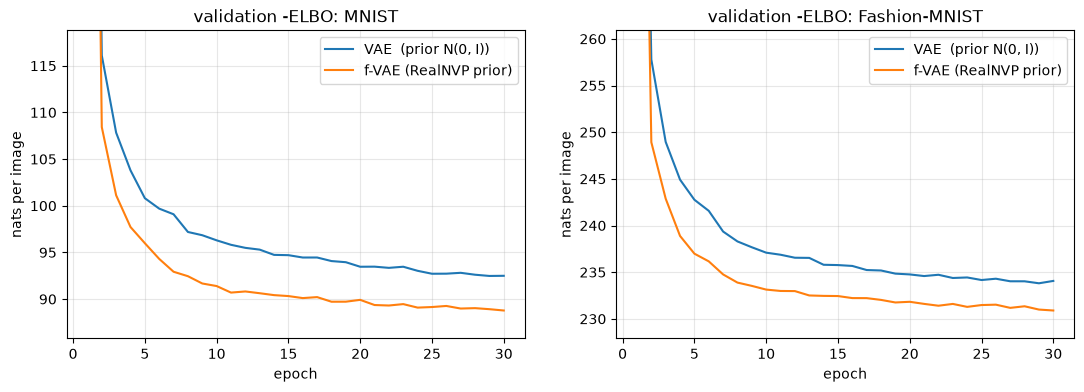

                 recon     kl   nelbo
VAE, MNIST       67.25  24.32   91.57
f-VAE, MNIST     65.62  22.25   87.86
VAE, Fashion    216.20  18.31  234.51
f-VAE, Fashion  215.06  16.44  231.50


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, h_vae, h_fvae, name in [(axes[0], hist_mnist, fhist_mnist, 'MNIST'),
                                (axes[1], hist_fashion, fhist_fashion, 'Fashion-MNIST')]:
    epochs = range(1, len(h_vae['val']) + 1)
    ax.plot(epochs, h_vae['val'], label='VAE  (prior N(0, I))')
    ax.plot(epochs, h_fvae['val'], label='f-VAE (RealNVP prior)')
    ax.set_ylim(min(h_fvae['val']) - 3, min(h_fvae['val']) + 30)
    ax.set_title(f'validation -ELBO: {name}')
    ax.set_xlabel('epoch'); ax.set_ylabel('nats per image')
    ax.grid(alpha=0.3); ax.legend()
plt.show()

torch.manual_seed(42)
table = pd.DataFrame({
    'VAE, MNIST':     evaluate_vae(vae_mnist, test_bin),
    'f-VAE, MNIST':   evaluate_fvae(fvae_mnist, test_bin),
    'VAE, Fashion':   evaluate_vae(vae_fashion, f_test_bin),
    'f-VAE, Fashion': evaluate_fvae(fvae_fashion, f_test_bin),
}).T
print(table.round(2))

## 29. GENERATED SAMPLES: VAE vs f-VAE
Same random seed on both sides. f-VAE: **u ~ N(0, I) → flow inverse → decoder.**

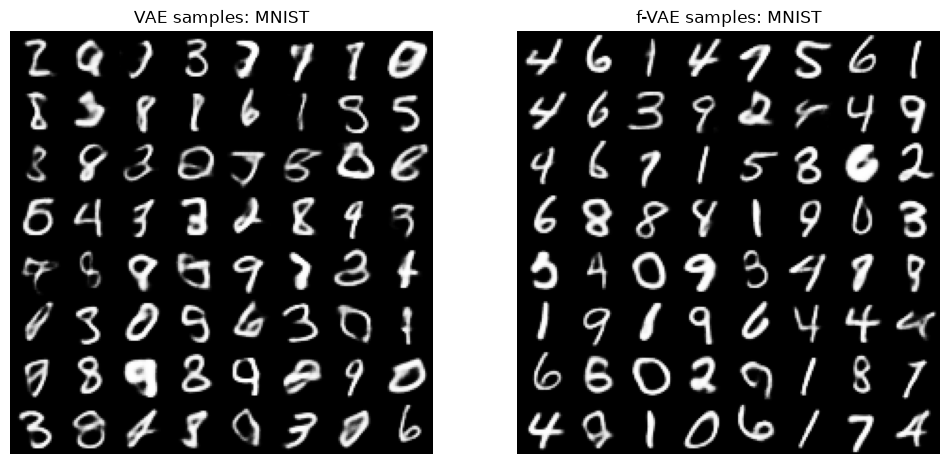

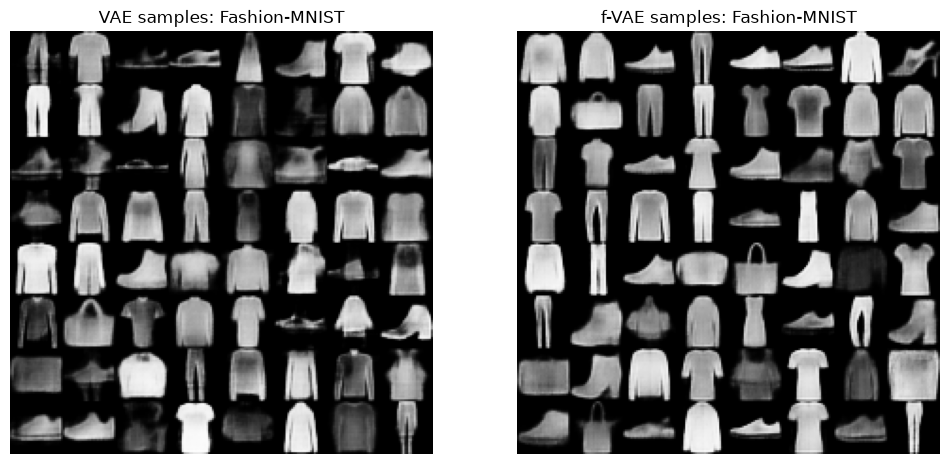

In [29]:
for vae_model, fvae_model, name in [(vae_mnist, fvae_mnist, 'MNIST'), (vae_fashion, fvae_fashion, 'Fashion-MNIST')]:
    vae_model.eval(); fvae_model.eval()
    with torch.no_grad():
        fig, axes = plt.subplots(1, 2, figsize=(12, 6))
        torch.manual_seed(42)
        show_grid(vae_model.sample(64), 8, axes[0], f'VAE samples: {name}')
        torch.manual_seed(42)
        show_grid(fvae_model.sample(64), 8, axes[1], f'f-VAE samples: {name}')
        plt.show()

## RESULT 4: THE FLOW PRIOR GIVES HIGHER LIKELIHOOD AND CLEANER SAMPLES

| test, nats per image | recon | KL | **−ELBO** |
|---|---|---|---|
| VAE, MNIST | 67.25 | 24.32 | 91.57 |
| **f-VAE, MNIST** | 65.62 | 22.25 | **87.86** (−3.7) |
| VAE, Fashion | 216.20 | 18.31 | 234.51 |
| **f-VAE, Fashion** | 215.06 | 16.44 | **231.50** (−3.0) |

**THE FLOW IS CORRECT:** invertible, and the log-det matches the real Jacobian exactly (1.523 = 1.523).

**f-VAE WINS ON BOTH DATASETS**, and it is ahead at **every epoch** of training, so this is not noise.
- **KL drops** (24.3 → 22.3): the learned prior sits **where the codes really are**, so describing them costs less.
- **Reconstruction also improves** (67.3 → 65.6): the encoder no longer has to squeeze codes into a round ball, so it can use the space more freely.

**SAMPLES ARE CLEANER:**
- **MNIST:** almost every f-VAE sample is a recognizable digit; the VAE has more broken or mixed ones. The flow sends `u ~ N(0, I)` to regions where real codes live, **avoiding the "prior holes"**.
- **Fashion:** cleaner, more distinct silhouettes (bags, heels, trousers), but **still blurry with no textures**. The prior only decides *which* z we sample; it can't add details the decoder never learned to draw.

**COST:** +0.63M parameters (+19%) and ~1.3× slower training.